In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

In [2]:
data_path = r"C:\Users\Ā\Documents\python_class\dataset\DC"

In [3]:
crashes = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/DC/DC/Crashes_2024_2025.geojson")
wards = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/DC/DC/Wards_from_2022.geojson")
tracts = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/DC/DC/Census_Tracts_in_2020.geojson")
clusters = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/DC/DC/Neighborhood_Clusters.geojson")

In [4]:
print("Crashes:", crashes.shape)
print("Wards:", wards.shape)
print("Census tracts:", tracts.shape)
print("Neighborhood clusters:", clusters.shape)

Crashes: (33748, 65)
Wards: (8, 21)
Census tracts: (206, 316)
Neighborhood clusters: (46, 12)


In [5]:
display(wards[["WARD", "NAME", "WARD_ID", "OBJECTID"]].head())
display(tracts[["TRACT", "GEOID", "NAME", "OBJECTID"]].head())
display(clusters[["NAME", "NBH_NAMES", "GIS_ID", "OBJECTID"]].head())

,WARD,NAME,WARD_ID,OBJECTID
0,8,Ward 8,8,1
1,6,Ward 6,6,2
2,7,Ward 7,7,3
3,2,Ward 2,2,4
4,1,Ward 1,1,5


,TRACT,GEOID,NAME,OBJECTID
0,002002,11001002002,Census Tract 20.02,1
1,002101,11001002101,Census Tract 21.01,2
2,002102,11001002102,Census Tract 21.02,3
3,002201,11001002201,Census Tract 22.01,4
4,002202,11001002202,Census Tract 22.02,5


,NAME,NBH_NAMES,GIS_ID,OBJECTID
0,Cluster 16,"Colonial Village, Shepherd Park, North Portal ...",NbhClusPly_1,1
1,Cluster 41,Rock Creek Park,NbhClusPly_2,2
2,Cluster 10,"Hawthorne, Barnaby Woods, Chevy Chase",NbhClusPly_3,3
3,Cluster 17,"Takoma, Brightwood, Manor Park",NbhClusPly_4,4
4,Cluster 40,Walter Reed,NbhClusPly_5,5


In [6]:

# ============================================================
# 6. CREATE A SMALLER CRASH DATASET
# ============================================================

crash_base = crashes[
    [
        "CRIMEID",
        "REPORTDATE",
        "ADDRESS",
        "LATITUDE",
        "LONGITUDE",
        "TOTAL_VEHICLES",
        "TOTAL_PEDESTRIANS",
        "TOTAL_BICYCLES",
        "SPEEDING_INVOLVED",
        "MAJORINJURIES_DRIVER",
        "MINORINJURIES_DRIVER",
        "MAJORINJURIES_PEDESTRIAN",
        "MINORINJURIES_PEDESTRIAN",
        "FATAL_DRIVER",
        "FATAL_PEDESTRIAN",
        "geometry"
    ]
].copy()

display(crash_base.head())


,CRIMEID,REPORTDATE,ADDRESS,LATITUDE,LONGITUDE,TOTAL_VEHICLES,TOTAL_PEDESTRIANS,TOTAL_BICYCLES,SPEEDING_INVOLVED,MAJORINJURIES_DRIVER,MINORINJURIES_DRIVER,MAJORINJURIES_PEDESTRIAN,MINORINJURIES_PEDESTRIAN,FATAL_DRIVER,FATAL_PEDESTRIAN,geometry
0,49236112798,2024-09-01 09:40:00+00:00,2350 SOUTH DAKOTA AVENUE NE,38.921815,-76.960829,2,0,0,0,0,0,0,0,0,0,POINT Z (-76.96028 38.92187 0)
1,53316040782,2024-12-05 22:00:00+00:00,"INTERSTATE 395 INTERSTATE BN\nWASHINGTON,",38.892032,-77.014022,2,0,0,0,0,0,0,0,0,0,POINT Z (-77.01402 38.89204 0)
2,53619941446,2024-01-03 09:55:00+00:00,1621 MONTANA AVENUE NE,38.921531,-76.981375,2,0,0,0,0,0,0,0,0,0,POINT Z (-76.98138 38.92154 0)
3,53620094830,2024-01-03 10:00:00+00:00,500 INDIANA AVENUE NW,38.894085,-77.018905,1,0,0,0,1,0,0,0,0,0,POINT Z (-77.01891 38.89409 0)
4,53620103358,2024-01-03 11:15:00+00:00,5601 POTOMAC AVENUE NW,38.930057,-77.110398,2,0,0,0,0,1,0,0,0,0,POINT Z (-77.11079 38.93011 0)


In [7]:

# ============================================================
# 7. SPATIAL JOIN WITH WARDS
# ============================================================

crash_ward = gpd.sjoin(
    crash_base,
    wards[
        ["WARD", "NAME", "geometry"]
    ],
    how="left",
    predicate="within"
)

display(
    crash_ward[
        ["CRIMEID", "ADDRESS", "WARD", "NAME"]
    ].head()
)



,CRIMEID,ADDRESS,WARD,NAME
0,49236112798,2350 SOUTH DAKOTA AVENUE NE,5.0,Ward 5
1,53316040782,"INTERSTATE 395 INTERSTATE BN\nWASHINGTON,",6.0,Ward 6
2,53619941446,1621 MONTANA AVENUE NE,5.0,Ward 5
3,53620094830,500 INDIANA AVENUE NW,6.0,Ward 6
4,53620103358,5601 POTOMAC AVENUE NW,3.0,Ward 3


In [8]:

# ------------------------------------------------------------
# 8. CHECK UNMATCHED CRASHES IN WARDS
# ------------------------------------------------------------

print(
    "Rows after the spatial join:",
    len(crash_ward)
)

print(
    "Crashes without a ward match:",
    crash_ward["WARD"].isna().sum()
)


Rows after the spatial join: 33767
Crashes without a ward match: 29


In [9]:

# ============================================================
# 9. COUNT CRASHES IN EACH WARD
# ============================================================

ward_counts = (
    crash_ward
    .dropna(subset=["WARD"])
    .groupby("WARD")
    .size()
    .reset_index(name="crash_count")
)

display(ward_counts)


,WARD,crash_count
0,1.0,2927
1,2.0,5647
2,3.0,1839
3,4.0,2883
4,5.0,5432
5,6.0,4722
6,7.0,5434
7,8.0,4854


In [10]:


# ------------------------------------------------------------
# 10. MERGE CRASH COUNTS BACK TO WARD POLYGONS
# ------------------------------------------------------------

ward_map = wards.merge(
    ward_counts,
    on="WARD",
    how="left"
)

ward_map["crash_count"] = (
    ward_map["crash_count"].fillna(0)
)



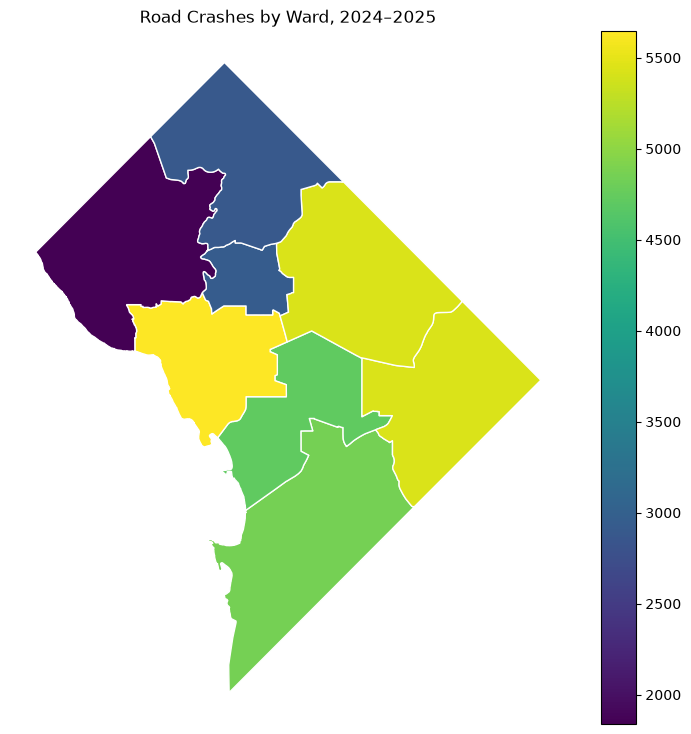

In [11]:

# ============================================================
# 11. CHOROPLETH — CRASHES BY WARD
# ============================================================

fig, ax = plt.subplots(figsize=(9, 9))

ward_map.plot(
    ax=ax,
    column="crash_count",
    legend=True,
    edgecolor="white"
)

ax.set_title(
    "Road Crashes by Ward, 2024–2025"
)

ax.set_axis_off()

plt.show()


In [12]:

# ============================================================
# 12. SPATIAL JOIN WITH CENSUS TRACTS
# ============================================================

crash_tract = gpd.sjoin(
    crash_base,
    tracts[
        ["TRACT", "GEOID", "NAME", "geometry"]
    ],
    how="left",
    predicate="within"
)

display(
    crash_tract[
        [
            "CRIMEID",
            "ADDRESS",
            "TRACT",
            "GEOID",
            "NAME"
        ]
    ].head()
)



,CRIMEID,ADDRESS,TRACT,GEOID,NAME
0,49236112798,2350 SOUTH DAKOTA AVENUE NE,011100,11001011100,Census Tract 111
1,53316040782,"INTERSTATE 395 INTERSTATE BN\nWASHINGTON,",980000,11001980000,Census Tract 9800
2,53619941446,1621 MONTANA AVENUE NE,009102,11001009102,Census Tract 91.02
3,53620094830,500 INDIANA AVENUE NW,005900,11001005900,Census Tract 59
4,53620103358,5601 POTOMAC AVENUE NW,000902,11001000902,Census Tract 9.02


In [13]:

# ------------------------------------------------------------
# 13. CHECK UNMATCHED CRASHES IN CENSUS TRACTS
# ------------------------------------------------------------

print(
    "Rows after the spatial join:",
    len(crash_tract)
)

print(
    "Crashes without a census-tract match:",
    crash_tract["GEOID"].isna().sum()
)


Rows after the spatial join: 33748
Crashes without a census-tract match: 320


In [14]:

# ============================================================
# 14. COUNT CRASHES BY CENSUS TRACT
# ============================================================

tract_counts = (
    crash_tract
    .dropna(subset=["GEOID"])
    .groupby("GEOID")
    .size()
    .reset_index(name="crash_count")
)

In [15]:

# ------------------------------------------------------------
# 15. MERGE COUNTS TO CENSUS TRACT POLYGONS
# ------------------------------------------------------------

tract_map = tracts.merge(
    tract_counts,
    on="GEOID",
    how="left"
)

tract_map["crash_count"] = (
    tract_map["crash_count"].fillna(0)
)


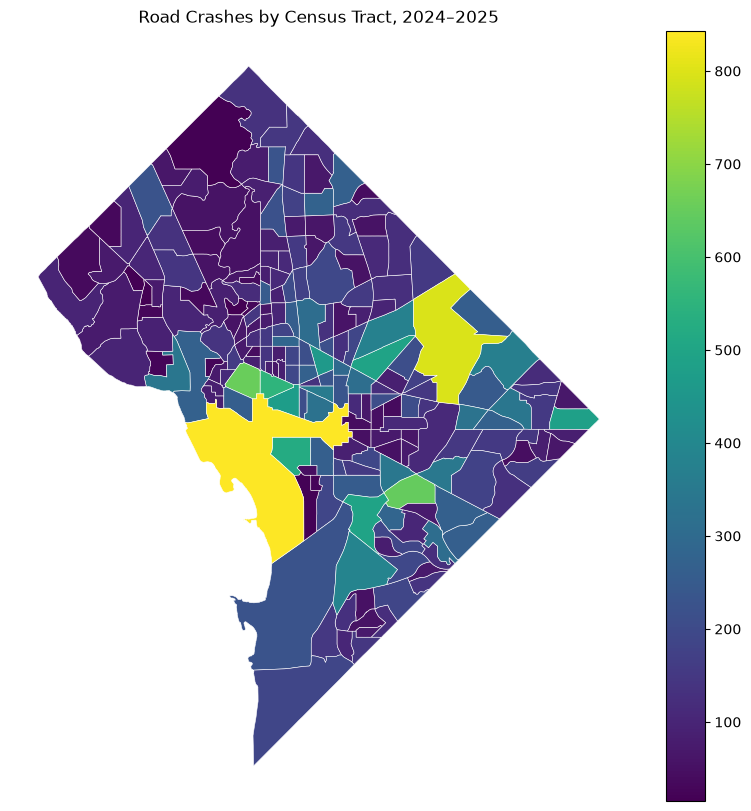

In [16]:
# ============================================================
# 16. CHOROPLETH — CRASHES BY CENSUS TRACT
# ============================================================

fig, ax = plt.subplots(figsize=(10, 10))

tract_map.plot(
    ax=ax,
    column="crash_count",
    legend=True,
    edgecolor="white",
    linewidth=0.4
)

ax.set_title(
    "Road Crashes by Census Tract, 2024–2025"
)

ax.set_axis_off()

plt.show()


In [17]:
# ============================================================
# 17. REPROJECT CENSUS TRACTS
# ============================================================

tract_area = tract_map.to_crs(
    epsg=32618
)

In [18]:

# ------------------------------------------------------------
# 18. CALCULATE AREA IN KM²
# ------------------------------------------------------------

tract_area["area_km2"] = (
    tract_area.geometry.area / 1_000_000
)

In [19]:
# ------------------------------------------------------------
# 19. CALCULATE CRASHES PER KM²
# ------------------------------------------------------------

tract_area["crashes_per_km2"] = (
    tract_area["crash_count"] /
    tract_area["area_km2"]
)

display(
    tract_area[
        [
            "TRACT",
            "NAME",
            "crash_count",
            "area_km2",
            "crashes_per_km2"
        ]
    ].head()
)

,TRACT,NAME,crash_count,area_km2,crashes_per_km2
0,002002,Census Tract 20.02,219,0.849342,257.846529
1,002101,Census Tract 21.01,175,0.600967,291.197547
2,002102,Census Tract 21.02,272,0.725940,374.686363
3,002201,Census Tract 22.01,72,0.415155,173.429153
4,002202,Census Tract 22.02,62,0.699425,88.644236


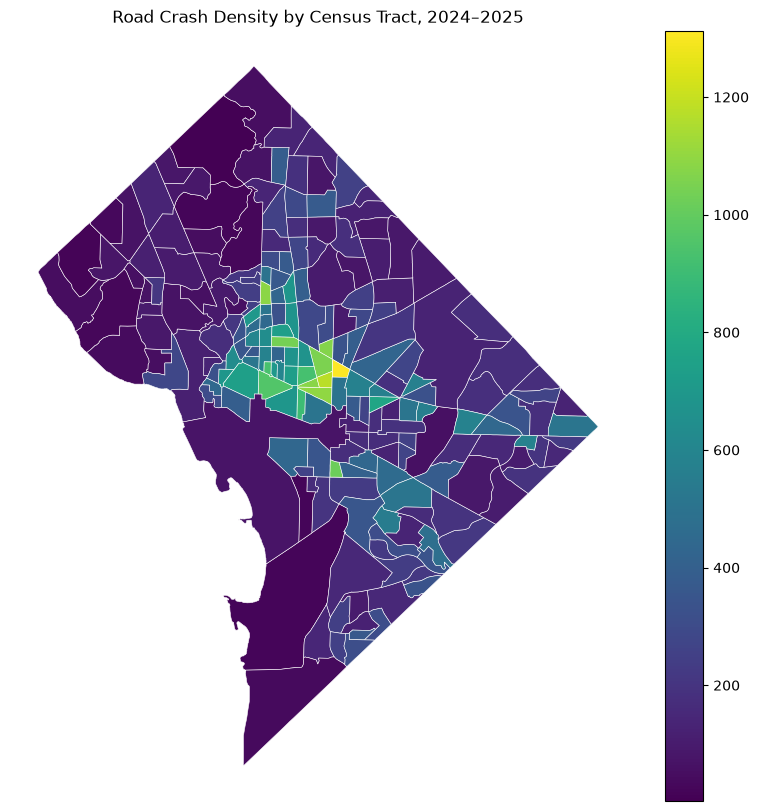

In [20]:
# ============================================================
# 20. CHOROPLETH — CRASH DENSITY BY CENSUS TRACT
# ============================================================

fig, ax = plt.subplots(figsize=(10, 10))

tract_area.plot(
    ax=ax,
    column="crashes_per_km2",
    legend=True,
    edgecolor="white",
    linewidth=0.4
)

ax.set_title(
    "Road Crash Density by Census Tract, 2024–2025"
)

ax.set_axis_off()

plt.show()


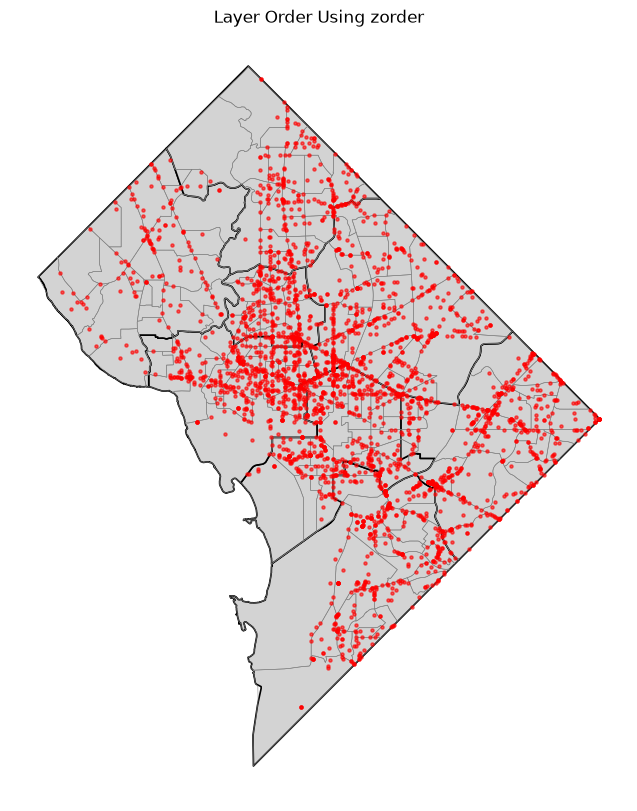

In [21]:
# ============================================================
# 21. ZORDER DEMONSTRATION
# ============================================================

crash_plot = crash_base.sample(
    3000,
    random_state=42
)

ward_z = 1
tract_z = 2
crash_z = 3


fig, ax = plt.subplots(figsize=(10, 10))

wards.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=1.2,
    zorder=ward_z
)

tracts.boundary.plot(
    ax=ax,
    color="gray",
    linewidth=0.4,
    zorder=tract_z
)

crash_plot.plot(
    ax=ax,
    color="red",
    markersize=5,
    alpha=0.6,
    zorder=crash_z
)

ax.set_title(
    "Layer Order Using zorder"
)

ax.set_axis_off()

plt.show()



In [22]:
# ============================================================
# 22. FOLIUM — CREATE INTERACTIVE MAP
# ============================================================

m = folium.Map(
    location=[38.9072, -77.0369],
    zoom_start=11,
    control_scale=True
)

m



In [23]:
# ============================================================
# 23. ADD WARD POLYGONS TO FOLIUM
# ============================================================

def ward_style(feature):
    return {
        "fillColor": "lightgray",
        "color": "black",
        "weight": 1.5,
        "fillOpacity": 0.15
    }


folium.GeoJson(
    wards[
        ["WARD", "NAME", "REP_NAME", "geometry"]
    ],
    name="Wards",
    style_function=ward_style,
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "WARD",
            "NAME",
            "REP_NAME"
        ],
        aliases=[
            "Ward number:",
            "Ward name:",
            "Representative:"
        ]
    )
).add_to(m)

In [24]:

# ============================================================
# 24. CREATE CRASH SAMPLE FOR FOLIUM
# ============================================================

crash_web = crashes.sample(
    1000,
    random_state=42
)[
    [
        "CRIMEID",
        "REPORTDATE",
        "ADDRESS",
        "TOTAL_VEHICLES",
        "TOTAL_PEDESTRIANS",
        "TOTAL_BICYCLES",
        "SPEEDING_INVOLVED",
        "MAJORINJURIES_DRIVER",
        "MINORINJURIES_DRIVER",
        "MAJORINJURIES_PEDESTRIAN",
        "MINORINJURIES_PEDESTRIAN",
        "FATAL_DRIVER",
        "FATAL_PEDESTRIAN",
        "geometry"
    ]
].copy()


crash_web["REPORTDATE"] = (
    crash_web["REPORTDATE"].astype(str)
)

crash_web["ADDRESS"] = (
    crash_web["ADDRESS"].fillna("Not recorded")
)

In [25]:
# ============================================================
# 25. ADD CRASH POINTS TO FOLIUM
# ============================================================

folium.GeoJson(
    crash_web,
    name="Crash sample",
    marker=folium.CircleMarker(
        radius=3,
        color="darkred",
        weight=1,
        fill=True,
        fill_opacity=0.7
    ),
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "CRIMEID",
            "REPORTDATE",
            "ADDRESS",
            "TOTAL_VEHICLES",
            "TOTAL_PEDESTRIANS",
            "TOTAL_BICYCLES",
            "SPEEDING_INVOLVED",
            "MAJORINJURIES_DRIVER",
            "MINORINJURIES_DRIVER",
            "MAJORINJURIES_PEDESTRIAN",
            "MINORINJURIES_PEDESTRIAN",
            "FATAL_DRIVER",
            "FATAL_PEDESTRIAN"
        ],
        aliases=[
            "Crash ID:",
            "Report date:",
            "Address:",
            "Vehicles involved:",
            "Pedestrians involved:",
            "Bicycles involved:",
            "Speeding involved:",
            "Major driver injuries:",
            "Minor driver injuries:",
            "Major pedestrian injuries:",
            "Minor pedestrian injuries:",
            "Driver fatalities:",
            "Pedestrian fatalities:"
        ],
        sticky=False
    )
).add_to(m)


# Display the interactive map
m

In [26]:
# ============================================================
#                  EXERCISE 15
#       SPATIAL JOIN WITH NEIGHBORHOOD CLUSTERS
# ============================================================


# ------------------------------------------------------------
# 26. SPATIAL JOIN
# ------------------------------------------------------------

crash_cluster = gpd.sjoin(
    crash_base,
    clusters[
        ["NAME", "NBH_NAMES", "geometry"]
    ],
    how="left",
    predicate="within"
)



In [27]:

# ------------------------------------------------------------
# 27. DISPLAY REQUIRED COLUMNS
# ------------------------------------------------------------

display(
    crash_cluster[
        [
            "CRIMEID",
            "ADDRESS",
            "NAME",
            "NBH_NAMES"
        ]
    ].head()
)



,CRIMEID,ADDRESS,NAME,NBH_NAMES
0,49236112798,2350 SOUTH DAKOTA AVENUE NE,Cluster 24,"Woodridge, Fort Lincoln, Gateway"
1,53316040782,"INTERSTATE 395 INTERSTATE BN\nWASHINGTON,",Cluster 45,"National Mall, Potomac River"
2,53619941446,1621 MONTANA AVENUE NE,Cluster 22,"Brookland, Brentwood, Langdon"
3,53620094830,500 INDIANA AVENUE NW,Cluster 8,"Downtown, Chinatown, Penn Quarters, Mount Vern..."
4,53620103358,5601 POTOMAC AVENUE NW,Cluster 13,"Spring Valley, Palisades, Wesley Heights, Foxh..."


In [28]:

# ------------------------------------------------------------
# 28. FIND UNMATCHED CRASH RECORDS
# ------------------------------------------------------------

print(
    "Crashes without a neighborhood-cluster match:",
    crash_cluster["NAME"].isna().sum()
)

Crashes without a neighborhood-cluster match: 41


In [29]:
# ------------------------------------------------------------
# 29. COUNT CRASHES IN EACH NEIGHBORHOOD CLUSTER
# ------------------------------------------------------------

cluster_counts = (
    crash_cluster
    .dropna(subset=["NAME"])
    .groupby("NAME")
    .size()
    .reset_index(name="crash_count")
)

display(cluster_counts)



,NAME,crash_count
0,Cluster 1,444
1,Cluster 10,274
2,Cluster 11,401
3,Cluster 12,169
4,Cluster 13,351
5,Cluster 14,356
6,Cluster 15,328
7,Cluster 16,133
8,Cluster 17,925
9,Cluster 18,1277


In [30]:
# ------------------------------------------------------------
# 30. MERGE COUNTS BACK TO CLUSTER POLYGONS
# ------------------------------------------------------------

cluster_map = clusters.merge(
    cluster_counts,
    on="NAME",
    how="left"
)

cluster_map["crash_count"] = (
    cluster_map["crash_count"].fillna(0)
)

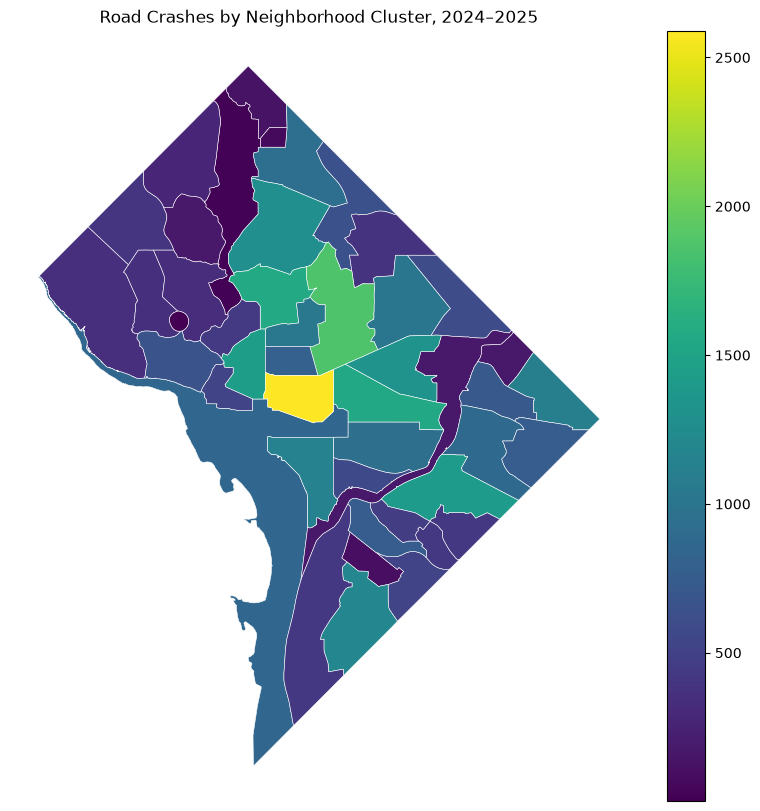

In [31]:
# ------------------------------------------------------------
# 31. CHOROPLETH — NUMBER OF CRASHES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 10))

cluster_map.plot(
    ax=ax,
    column="crash_count",
    legend=True,
    edgecolor="white",
    linewidth=0.4
)

ax.set_title(
    "Road Crashes by Neighborhood Cluster, 2024–2025"
)

ax.set_axis_off()

plt.show()


In [32]:

# ------------------------------------------------------------
# 32. REPROJECT TO EPSG:32618
# ------------------------------------------------------------

cluster_area = cluster_map.to_crs(
    epsg=32618
)


In [33]:

# ------------------------------------------------------------
# 33. CALCULATE AREA IN SQUARE KILOMETRES
# ------------------------------------------------------------

cluster_area["area_km2"] = (
    cluster_area.geometry.area / 1_000_000
)



In [34]:
# ------------------------------------------------------------
# 34. CALCULATE CRASHES PER KM²
# ------------------------------------------------------------

cluster_area["crashes_per_km2"] = (
    cluster_area["crash_count"] /
    cluster_area["area_km2"]
)


# Display the results
display(
    cluster_area[
        [
            "NAME",
            "NBH_NAMES",
            "crash_count",
            "area_km2",
            "crashes_per_km2"
        ]
    ].head()
)



,NAME,NBH_NAMES,crash_count,area_km2,crashes_per_km2
0,Cluster 16,"Colonial Village, Shepherd Park, North Portal ...",133,2.245697,59.224375
1,Cluster 41,Rock Creek Park,15,6.589366,2.276395
2,Cluster 10,"Hawthorne, Barnaby Woods, Chevy Chase",274,4.944244,55.417973
3,Cluster 17,"Takoma, Brightwood, Manor Park",925,4.479685,206.487729
4,Cluster 40,Walter Reed,63,0.479942,131.265726


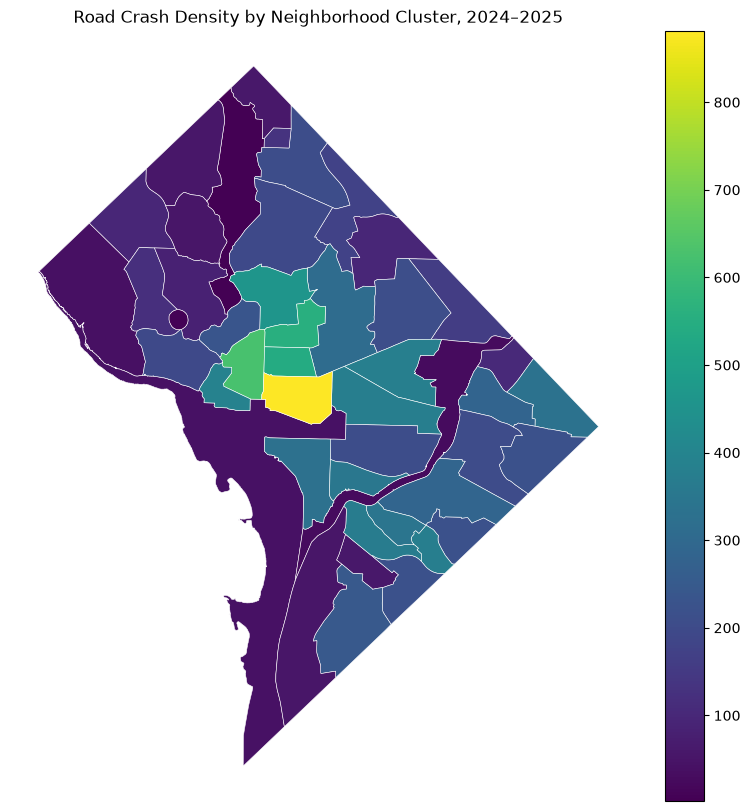

In [35]:

# ------------------------------------------------------------
# 35. CHOROPLETH — CRASH DENSITY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 10))

cluster_area.plot(
    ax=ax,
    column="crashes_per_km2",
    legend=True,
    edgecolor="white",
    linewidth=0.4
)

ax.set_title(
    "Road Crash Density by Neighborhood Cluster, 2024–2025"
)

ax.set_axis_off()
plt.show()